In [12]:
!pip install numpy
!pip install matplotlib
!pip install pandas
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


In [13]:
import pandas as pd

cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "w",            # Velocity Beam1|X|East (m/s) orginally u renamed to w to reflect vertical velocities
    "u",            # Velocity Beam2|Y|North (m/s) originally v now renamed to u to reflect crossh shore velocities
    "v",            # Velocity Beam3|Z|Up (m/s) orginally w now renamed to v to reflect alongshore velocities
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "analog1",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]

#U=cross shore velocity
#V=along shore velocity 
#W=vertical velocity

df = pd.read_csv("SSC01.dat", sep=r"\s+", header=None, names=cols)

In [14]:
df["t"] = df.index / 16
start = pd.Timestamp("2026-09-29 06:00:00")
df["time"] = start + pd.to_timedelta(df["t"], unit="s")

In [15]:
DAY = start.strftime("%Y-%m-%d")   

manoeuvres = {
    "A1-11": "07:40:22",
    "A1-12": "07:46:51",
    "A2-11": "07:57:17",
    "A2-12": "08:02:11",
    "A3-11": "08:07:25",
    "A3-12": "08:12:08",
    "B-11":  "08:17:53",
    "B-12":  "08:23:40",
    "C-11":  "08:40:40",
    "C-12":  "08:45:57",
    "E-11":  "08:51:35",
    "E-12":  "08:57:08",
    
    "A1-21": "09:02:35",
    "A1-22": "09:07:47",
    "A2-21": "09:19:14",
    "A2-22": "09:29:27",
    "A3-21": "09:29:27",
    "A3-22": "09:35:17",
    "B-21":  "09:42:33",
    "B-22":  "09:49:34",
    "C-21":  "09:55:04",
    "C-22":  "09:58:54",
    "E-21":  "10:02:51",
    "E-22":  "10:06:45",

    "A1-31": "10:15:16",
    "A2-31": "10:17:03",
    "A3-31": "10:19:05",
    "B-31":  "10:22:36",
    "C-31":  "10:25:25",
    "E-31":  "10:31:33",
    "D-31":  "10:37:55",
    "D-32":  "10:41:15",
    "D-33":  "10:44:33",
    "F-31":  ["10:47:49", "10:48:31","10:49:06", "10:49:44"], #time of 3rd pass 
    "F-32":  ["10:52:31", "10:53:11","10:53:57", "10:53:41"],  #time of 3rd pass
    "F-33":  ["10:58:47", "10:59:37", "11:00:27", "11:01:18"], #time of 3rd pass

    "A1-41": "07:52:21",
    "B-41":  "08:29:40",
    "B-42":  "08:36:05",
    "A2-41": "09:24:16",
    "E-41": "10:10:30",
    "C-41": "10:28:22",
    "A1-41": "10:34:17",
    "F-41": ["11:04:24", "11:05:04", "11:05:41", "11:06:18"]
}

In [16]:
import matplotlib.dates as mdates

def despike(s, window=101, k=4):
    med = s.rolling(window, center=True, min_periods=1).median()
    dev = s - med
    return s.where(dev.abs() <= k * dev.std())

def plot_uvw(data, start, end, window=101, k=4, filter_peaks=True):
    t_start = pd.Timestamp(f"{DAY} {start}")
    t_end   = pd.Timestamp(f"{DAY} {end}")

    part = data[(data["time"] >= t_start) & (data["time"] <= t_end)].copy()

    if filter_peaks:
        for comp in ["u", "v", "w"]:
            before = part[comp].notna().sum()
            part[comp] = despike(part[comp], window, k)
            print(f"{comp}: removed {before - part[comp].notna().sum()} peaks")

    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for ax, comp in zip(axes, ["corr1", "corr2", "corr3"]):
        ax.plot(part["time"], part[comp], lw=0.5, color="#0033cc", label="raw")
        ax.set_ylabel(comp)
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel("Time (HH:MM)")

    for name, t in manoeuvres.items():
        if isinstance(t, str):
            t = [t]
        xs = [pd.Timestamp(f"{DAY} {x}") for x in t]
        xs = [x for x in xs if t_start <= x <= t_end]
        if not xs:
            continue
        for x in xs:
            for ax in axes:
                ax.axvline(x, color="k", ls="--", lw=0.6)
        mid = xs[0] + (xs[-1] - xs[0]) / 2
        axes[0].text(mid, 1.01, name, transform=axes[0].get_xaxis_transform(),
                     rotation=90, ha="center", va="bottom", fontsize=13, fontweight="bold",
                     color="darkred", bbox=dict(boxstyle="round,pad=0.2", fc="lightyellow", ec="darkred", lw=0.8))

    axes[-1].set_xlim(t_start, t_end)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout()
    plt.show()

In [27]:
def plot_sediment(data, start, end, window=101, k=4, filter_peaks=True):
    t_start = pd.Timestamp(f"{DAY} {start}")
    t_end   = pd.Timestamp(f"{DAY} {end}")

    part = data[(data["time"] >= t_start) & (data["time"] <= t_end)].copy()

    comp = "analog1"
    if filter_peaks:
        before = part[comp].notna().sum()
        part[comp] = despike(part[comp], window, k)
        print(f"{comp}: removed {before - part[comp].notna().sum()} peaks")

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(part["time"], part[comp], lw=0.5, color="#0033cc", label="raw")
    ax.set_ylabel("OBS")
    ax.set_xlabel("Time (HH:MM)")
    ax.grid(True, alpha=0.3)

    for name, t in manoeuvres.items():
        if isinstance(t, str):
            t = [t]
        xs = [pd.Timestamp(f"{DAY} {x}") for x in t]
        xs = [x for x in xs if t_start <= x <= t_end]
        if not xs:
            continue
        for x in xs:
            ax.axvline(x, color="k", ls="--", lw=0.6)
        mid = xs[0] + (xs[-1] - xs[0]) / 2
        ax.text(mid, 0.93, name, transform=ax.get_xaxis_transform(),
                rotation=0, ha="center", va="bottom", fontsize=13, fontweight="bold",
                     color="black", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", lw=0.8))

    ax.set_xlim(t_start, t_end)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout()
    plt.show()

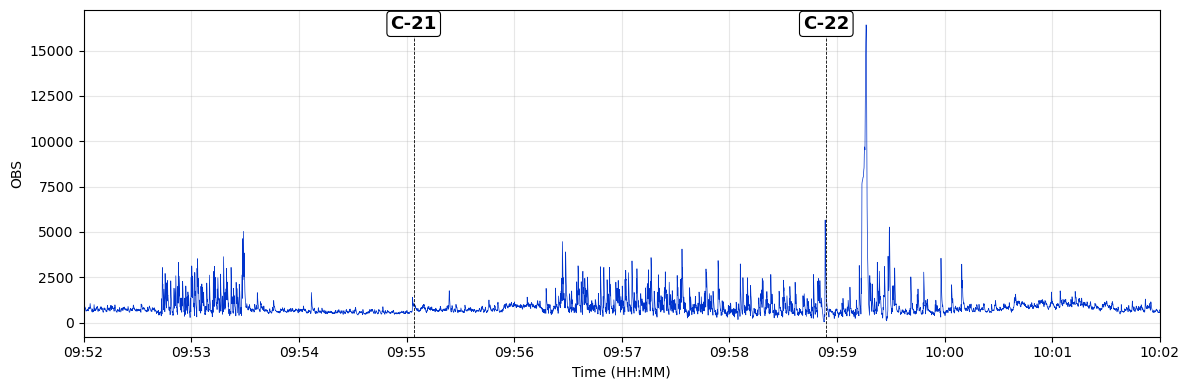

In [28]:
#plot_uvw(df, "10:00", "11:10", filter_peaks=False)
#plot_uvw(df, "08:00", "09:30", filter_peaks=False)              # stricter peak filter
#plot_uvw(df, "08:00", "09:30", filter_peaks=False)  # no filtering
plot_sediment(df, "09:52", "10:02", filter_peaks=False)

In [ ]:
plot_sediment(df, "09:52", "10:02", filter_peaks=False)

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=cb8feeb3-afee-4b20-ab89-f0abd9348b44' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>